In [1]:
!pip install -q ultralytics opencv-python matplotlib

Width: 1080
Height: 1920
FPS: 23.976023976023978


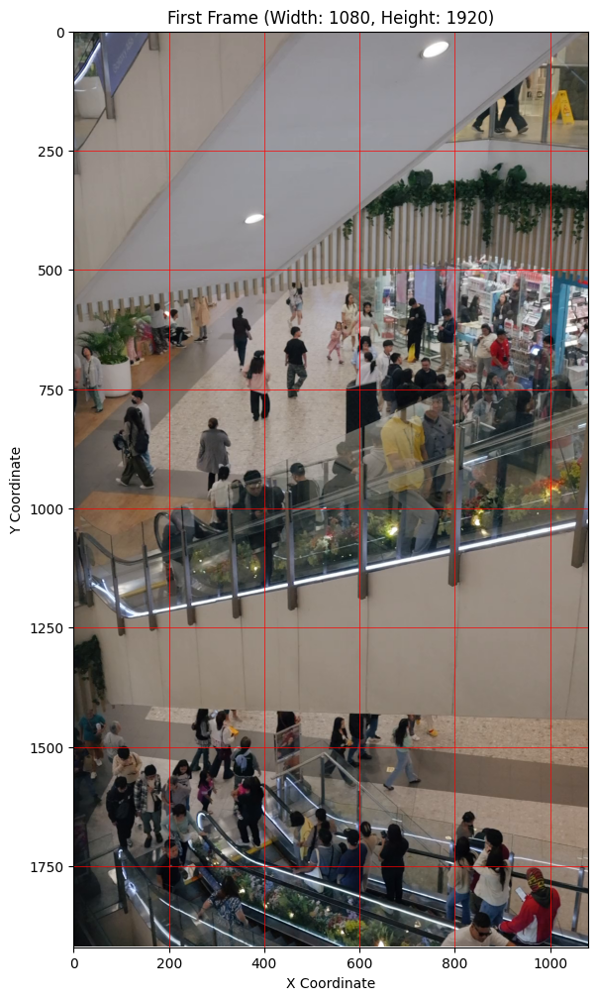

In [2]:
import cv2
import matplotlib.pyplot as plt

video_path = "/content/15313088_1080_1920_24fps.mp4"

cap = cv2.VideoCapture(video_path)
assert cap.isOpened(), "Error reading video file"

w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

print("Width:", w)
print("Height:", h)
print("FPS:", fps)

success, frame = cap.read()
cap.release()

if success:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 12))
    plt.imshow(frame_rgb)
    plt.grid(True, color="red", linewidth=0.5)
    plt.title(f"First Frame (Width: {w}, Height: {h})")
    plt.xlabel("X Coordinate")
    plt.ylabel("Y Coordinate")
    plt.xlim(0, w)
    plt.ylim(h, 0)
    plt.show()

People detected: 52


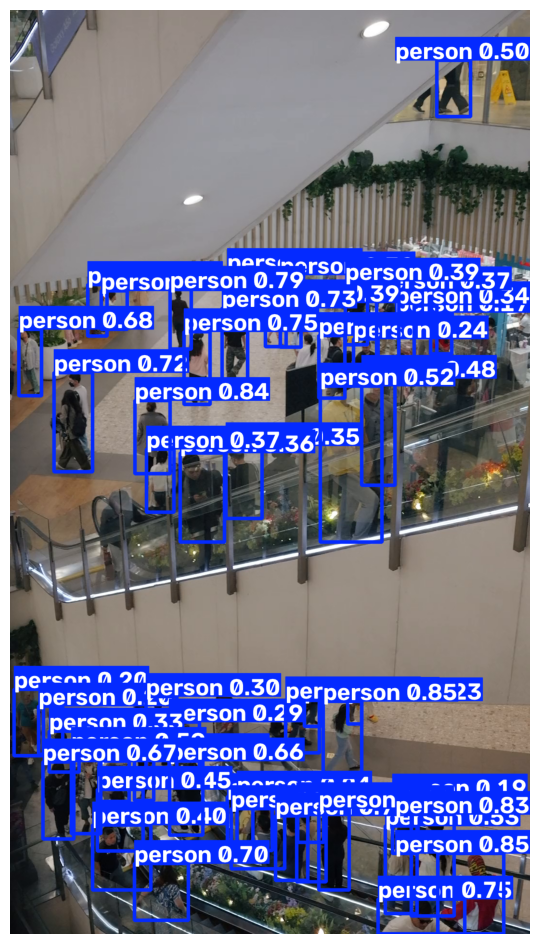

In [8]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

model = YOLO("yolov8n.pt")

cap = cv2.VideoCapture(video_path)
success, frame = cap.read()
cap.release()

results = model.predict(
    source=frame,
    classes=[0],
    conf=0.15,
    imgsz=1280,
    verbose=False
)

print("People detected:", len(results[0].boxes))

annotated_frame = results[0].plot()

plt.figure(figsize=(9, 12))
plt.imshow(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

Ultralytics Solutions: ✅ {'source': None, 'model': 'yolov8n.pt', 'classes': [0], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': None, 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (540, 960), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': None, 'conf': 0.15, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 1280, 'tracker': 'tracktrack.yaml', 'verbose': True, 'data': 'images', 'recognizer': 'paddleocr'}
0: 1280x1280 15.0ms, 11 person
Speed: 691.4ms track, 15.0ms solution per image at shape (1, 3, 1280, 1280)

People tracked: 11


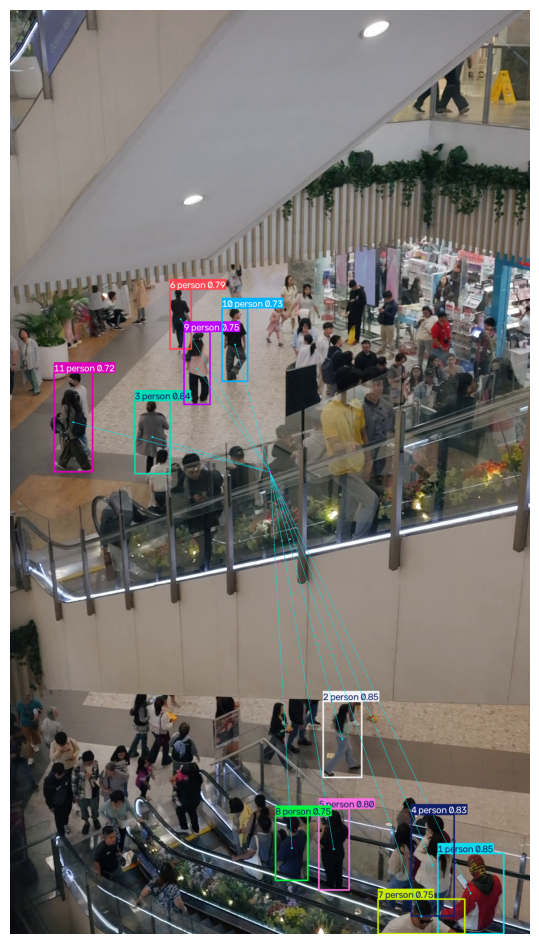

In [9]:
from ultralytics import solutions

visioneye_test = solutions.VisionEye(
    model="yolov8n.pt",
    classes=[0],
    vision_point=(540, 960),
    conf=0.15,
    imgsz=1280,
    show=False
)

vision_results = visioneye_test(frame)

print("People tracked:", vision_results.total_tracks)

plt.figure(figsize=(9, 12))
plt.imshow(
    cv2.cvtColor(vision_results.plot_im, cv2.COLOR_BGR2RGB)
)
plt.axis("off")
plt.show()

In [10]:
from ultralytics import solutions
import cv2

visioneye = solutions.VisionEye(
    model="yolov8n.pt",
    classes=[0],
    vision_point=(540, 960),
    conf=0.15,
    imgsz=1280,
    show=False
)

print("VisionEye initialized successfully!")

Ultralytics Solutions: ✅ {'source': None, 'model': 'yolov8n.pt', 'classes': [0], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': None, 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (540, 960), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': None, 'conf': 0.15, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 1280, 'tracker': 'tracktrack.yaml', 'verbose': True, 'data': 'images', 'recognizer': 'paddleocr'}
VisionEye initialized successfully!


In [11]:
# Open the original video
cap = cv2.VideoCapture(video_path)

# Get video properties
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

# Create output video
output_path = "visioneye_output.mp4"

video_writer = cv2.VideoWriter(
    output_path,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (w, h)
)

assert video_writer.isOpened(), "Error creating output video!"

# Initialize a fresh VisionEye instance
visioneye = solutions.VisionEye(
    model="yolov8n.pt",
    classes=[0],
    vision_point=(540, 960),
    conf=0.15,
    imgsz=1280,
    show=False
)

frame_count = 0

# Process video frame by frame
while cap.isOpened():

    success, frame = cap.read()

    if not success:
        break

    results = visioneye(frame)

    # Save the annotated frame
    video_writer.write(results.plot_im)

    frame_count += 1

    if frame_count % 100 == 0:
        print("Processed frames:", frame_count)

# Release resources
cap.release()
video_writer.release()
cv2.destroyAllWindows()

print("Video processing completed!")
print("Total frames processed:", frame_count)
print("Output saved as:", output_path)

Ultralytics Solutions: ✅ {'source': None, 'model': 'yolov8n.pt', 'classes': [0], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': None, 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (540, 960), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': None, 'conf': 0.15, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 1280, 'tracker': 'tracktrack.yaml', 'verbose': True, 'data': 'images', 'recognizer': 'paddleocr'}
0: 1280x1280 3.5ms, 11 person
Speed: 519.0ms track, 3.5ms solution per image at shape (1, 3, 1280, 1280)

1: 1280x1280 3.8ms, 11 person
Speed: 775.3ms track, 3.8ms solution per image at shape (1, 3, 1280, 1280)

2: 1280x1280 1.6ms, 11 person
Speed: 717.7ms track, 1.6ms solution per

In [12]:
from IPython.display import Video, display

display(Video(output_path, embed=True))

In [13]:
from google.colab import files

files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>